# Laptop Price Prediction
الخطوات: تنضيف ← اسم مختصر للاب ← EDA ← Pipeline ← مقارنة موديلات ← حفظ الموديل للـ API

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.model_selection import train_test_split, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from catboost import CatBoostRegressor
except ImportError:
    CatBoostRegressor = None
    print('catboost not installed -> it will be skipped (pip install catboost)')

## 1) تحميل الداتا

In [2]:
CSV_PATH = r'E:\University\ML_Datasets\laptops.csv'

df = pd.read_csv(CSV_PATH)
df = df.drop('id', axis=1)
print(df.shape)
df.isna().sum()

(2160, 12)


Laptop             0
Status             0
Brand              0
Model              0
CPU                0
RAM                0
Storage            0
Storage type      42
GPU             1371
Screen             4
Touch              0
Final Price        0
dtype: int64

## 2) التنضيف (كله قبل الـ split)

In [3]:
print(df['Status'].unique(), df['Touch'].unique())

# Status and Touch -> 0/1
df['Status'] = (df['Status'] == 'New').astype(int)      # New = 1, Refurbished = 0
df['Touch'] = (df['Touch'] == 'Yes').astype(int)

# Storage: 0 means missing, then unify the sizes
df['Storage'] = df['Storage'].replace(0, np.nan)
df['Storage'] = df['Storage'].replace({1000: 1024, 500: 512, 2000: 2048, 3000: 3072, 240: 256, 4000: 4096})
df = df.dropna(subset=['Storage']).copy()
df['Storage'] = df['Storage'].astype(int)

# Storage type: Chromebook -> eMMC, any other missing value -> SSD
is_chromebook = df['Laptop'].str.contains('Chromebook', case=False)
df.loc[df['Storage type'].isna() & is_chromebook, 'Storage type'] = 'eMMC'
df['Storage type'] = df['Storage type'].fillna('SSD')

# GPU: no GPU listed -> integrated graphics
df['GPU'] = df['GPU'].fillna('Integrated')

# Screen: drop rows with no screen size
df = df.dropna(subset=['Screen']).copy()

print(df.shape)
df['Storage'].unique()

['New' 'Refurbished'] ['No' 'Yes']
(2155, 12)


array([ 512,  256, 1024,   64,  128,   32, 2048, 4096, 3072])

In [4]:
# CPU: keep only the useful part (i5, Ryzen 7, M1 ...). "Evo i7" and "i7" are the same family
for word in ['Intel ', 'Core ', 'AMD ', 'Mediatek ', 'MediaTek ', 'Qualcomm ', 'Microsoft ', 'Apple ', 'Evo ']:
    df['CPU'] = df['CPU'].str.replace(word, '', regex=False)

df['CPU'].unique()

array(['i5', 'Celeron', 'i3', 'i7', 'Ryzen 5', 'Ryzen 7', 'Ryzen 3', 'M1',
       'Athlon', 'M2', 'Ryzen 9', 'i9', '3020e', 'Snapdragon 7',
       'Pentium', 'M2 Pro', 'Radeon 5', '3015e', 'M1 Pro', 'M3',
       'Radeon 9', 'MT8183', '3015Ce', 'Snapdragon 8', 'SQ1'],
      dtype=object)

In [5]:
# quick look at the strange CPU values
df[df['CPU'].str.contains('Radeon')][['Laptop', 'CPU', 'Final Price']]

,Laptop,CPU,Final Price
569,"Alurin AMD R5 5500U 15.6"" 8 256 con SO",Radeon 5,499.00
1203,ASUS ROG Strix Scar 17 G733PZ-R97B48PB1 AMD R...,Radeon 9,4753.32
1245,ASUS ROG Strix Scar 17 G733PY-R97B49PB1 AMD R...,Radeon 9,5630.90


In [6]:
# all text columns -> lowercase, so the data and the API use the same format
# (we keep a nice label for each value to show it in the dropdowns, e.g. 'hp' -> 'HP')
text_cols_all = ['Brand', 'CPU', 'GPU', 'Storage type']
labels = {c: dict(zip(df[c].str.strip().str.lower(), df[c].str.strip())) for c in text_cols_all}

for c in text_cols_all:
    df[c] = df[c].str.strip().str.lower()

df[text_cols_all].head()

,Brand,CPU,GPU,Storage type
0,asus,i5,integrated,ssd
1,alurin,celeron,integrated,ssd
2,asus,i3,integrated,ssd
3,msi,i7,rtx 3050,ssd
4,hp,i5,integrated,ssd


## 3) اسم مختصر للاب (`Name`)
عمود `Laptop` الأصلي فاضل زي ما هو، وبنعمل عمود جديد `Name` من غير الـ CPU والرام والتخزين والشاشة وأكواد المنتج.

In [7]:
cpu_words = r'\b(Intel|AMD|Apple|Mediatek|MediaTek|Qualcomm|Microsoft|Snapdragon|Core|Ryzen|Celeron|Pentium|Athlon|SQ1|M[123])\b'
screen_words = {'FHD', 'FHD+', 'QHD', 'QHD+', 'UHD', 'WQHD', 'WUXGA', 'WQXGA', '4K', 'OLED', 'IPS', 'HD', 'TOUCH', 'TOUCHSCREEN', 'RETINA'}


def short_name(laptop, model):
    name = str(laptop).split('/')[0]              # everything after the first / is specs
    first, _, rest = name.partition(' ')          # first word is the brand
    match = re.search(cpu_words, rest)
    if match:
        rest = rest[:match.start()]               # cut from the CPU name

    words = [first]
    for w in rest.split():
        if w.upper() in screen_words or re.fullmatch(r'\d+Hz', w, re.I):
            continue                              # screen words (FHD, OLED, 144Hz ...)
        if re.fullmatch(r'\d{4,}', w):
            continue                              # plain model numbers (9520, 3520 ...)
        if '-' in w and re.search(r'\d', w):      # product codes like 12UC-082XES or 16-d1038ns
            w = w.split('-')[0]
            if len(w) > 3:
                continue
        elif len(w) >= 6 and re.search(r'\d', w) and re.search(r'[A-Za-z]', w):
            continue                              # long codes like 15IAU7
        if len(words) > 1 and re.fullmatch(r'[A-Z]{3}', w) and re.search(r'\d', words[-1]):
            continue                              # 3-letter codes after a model number (IGL, ABA ...)
        words.append(w)

    if len(words) < 2:                            # nothing left -> use the Model column
        words.append(str(model))
    return ' '.join(words)


df['Name'] = df.apply(lambda r: short_name(r['Laptop'], r['Model']), axis=1)

print('unique short names:', df['Name'].nunique())
df[['Laptop', 'Name']].sample(15, random_state=1)

unique short names: 657


,Laptop,Name
415,Lenovo IdeaPad Gaming 3 15ACH6 AMD Ryzen 5 560...,Lenovo IdeaPad Gaming 3
1243,ASUS ROG Strix G15 G513RW-HQ133 AMD Ryzen 9 69...,ASUS ROG Strix G15
1923,HP ZBook Firefly 15 G8 Intel Core i7-1165G7/16...,HP ZBook Firefly 15 G8
242,Acer Nitro 5 AN515-45-R6CN AMD Ryzen 7 5800H/3...,Acer Nitro 5
134,Lenovo Legion 5 15IAH7H Intel Core i7-12700H/1...,Lenovo Legion 5
1014,Apple MacBook Pro Intel Core i5 1.4GHz/8GB/256...,Apple MacBook Pro
1890,HP EliteBook 840 G8 Intel Core i7-1165G7/16GB/...,HP EliteBook 840 G8
1265,ASUS ZenBook 14 OLED UM3402YA-KM464WS AMD Ryze...,ASUS ZenBook 14
448,Gigabyte AORUS 5 SE4-73ES214SD Intel Core i7-1...,Gigabyte AORUS 5 SE4
165,Lenovo Ideapad Gaming 3 Gen 6 Intel Core i5-11...,Lenovo Ideapad Gaming 3 Gen 6


## EDA

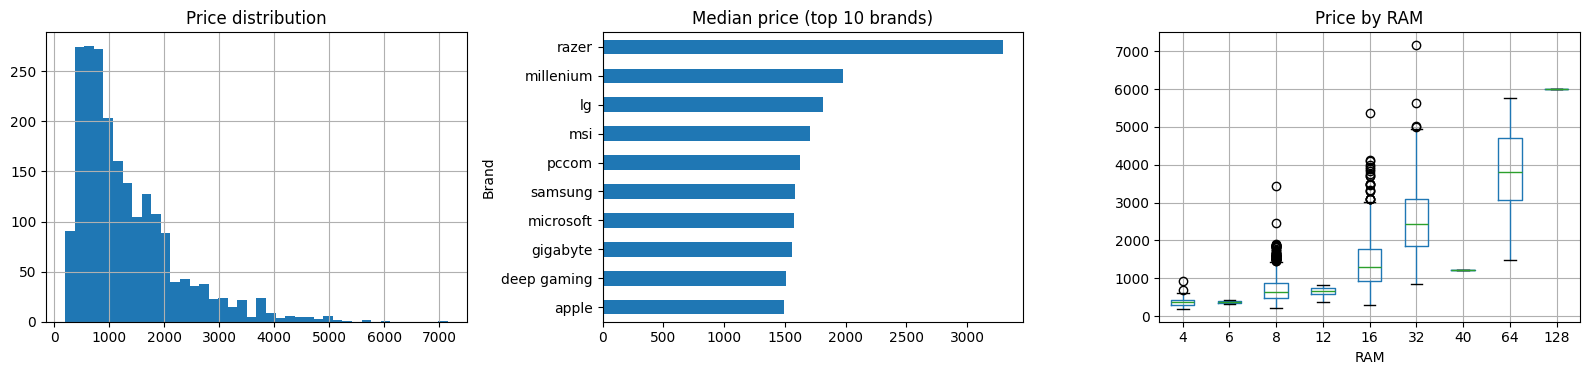

price skew: 1.652320183261493
duplicated rows: 0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df['Final Price'].hist(bins=40, ax=axes[0])
axes[0].set_title('Price distribution')

df.groupby('Brand')['Final Price'].median().sort_values().tail(10).plot(kind='barh', ax=axes[1])
axes[1].set_title('Median price (top 10 brands)')

df.boxplot(column='Final Price', by='RAM', ax=axes[2])
axes[2].set_title('Price by RAM')

plt.suptitle('')
plt.tight_layout()
plt.show()

print('price skew:', df['Final Price'].skew())
print('duplicated rows:', df.duplicated().sum())

## 4) Pipeline
عمود `Laptop` و `Name` مش داخلين في الموديل (الاسم فيه المواصفات كلها)، بس فاضلين في الداتا عشان الـ API.

In [9]:
num_cols = ['RAM', 'Storage', 'Screen']
cat_cols = ['Brand', 'CPU', 'GPU', 'Storage type']
bin_cols = ['Status', 'Touch']
features = num_cols + cat_cols + bin_cols

X = df[features]
y = df['Final Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


def make_preprocessor(cat_columns=cat_cols):
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_columns),
        ('bin', 'passthrough', bin_cols)
    ])


def build(model, log_target=False, cat_columns=cat_cols):
    pipe = Pipeline([('prep', make_preprocessor(cat_columns)), ('model', model)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return TransformedTargetRegressor(regressor=pipe)

## 5) مقارنة الموديلات (cross-validation على الـ train بس)
كل موديل بنجربه مرتين: السعر عادي، والسعر بعد `log`.

In [10]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}
if CatBoostRegressor is not None:
    models['CatBoost'] = CatBoostRegressor(verbose=0, random_state=42)

rows = []
for name, model in models.items():
    for log_target in [False, True]:
        est = build(model, log_target)
        scores = cross_validate(est, X_train, y_train, cv=5,
                                scoring=['r2', 'neg_mean_absolute_error'])
        rows.append({
            'model': name,
            'log_target': log_target,
            'R2': scores['test_r2'].mean(),
            'MAE': -scores['test_neg_mean_absolute_error'].mean()
        })

results = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
results

,model,log_target,R2,MAE
0,CatBoost,True,0.842608,224.704286
1,CatBoost,False,0.839532,233.320006
2,Random Forest,True,0.794406,245.131323
3,Random Forest,False,0.803743,245.846135
4,Linear Regression,False,0.817371,262.115609
5,Linear Regression,True,0.717359,265.180652
6,Gradient Boosting,True,0.784707,268.715546
7,Gradient Boosting,False,0.797046,276.642482


In [11]:
# does the Model column help? (just a check, it is not used in the final model)
for use_model in [False, True]:
    cols_all = features + (['Model'] if use_model else [])
    cat_used = cat_cols + (['Model'] if use_model else [])
    est = build(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), False, cat_used)
    scores = cross_validate(est, df.loc[X_train.index, cols_all], y_train, cv=5, scoring='r2')
    print('with Model   ' if use_model else 'without Model', round(scores['test_score'].mean(), 4))

without Model 0.8037
with Model    0.8188


best model: CatBoost | log target: True
{'regressor__model__learning_rate': 0.1, 'regressor__model__iterations': 800, 'regressor__model__depth': 6}
MAE : 248.1
RMSE: 430.84
R2  : 0.7893


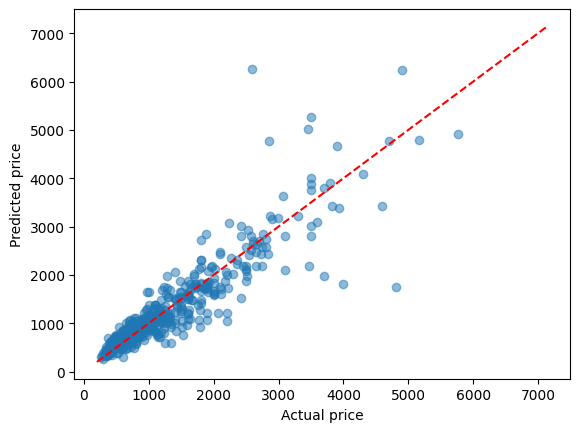

In [12]:
best = results.iloc[0]
best_name, best_log = best['model'], bool(best['log_target'])
print('best model:', best_name, '| log target:', best_log)

param_grids = {
    'Linear Regression': {},
    'Random Forest': {
        'regressor__model__n_estimators': [100, 200, 300],
        'regressor__model__max_depth': [None, 10, 20],
        'regressor__model__min_samples_leaf': [1, 2, 4],
    },
    'Gradient Boosting': {
        'regressor__model__n_estimators': [100, 200, 300],
        'regressor__model__learning_rate': [0.05, 0.1, 0.2],
        'regressor__model__max_depth': [2, 3, 4],
    },
    'CatBoost': {
        'regressor__model__iterations': [300, 500, 800],
        'regressor__model__depth': [4, 6, 8],
        'regressor__model__learning_rate': [0.03, 0.05, 0.1],
    },
}

estimator = build(models[best_name], best_log)

if param_grids[best_name]:
    search = RandomizedSearchCV(estimator, param_grids[best_name], n_iter=10, cv=3,
                                scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    final_model = search.best_estimator_
    print(search.best_params_)
else:
    final_model = estimator.fit(X_train, y_train)

# evaluation on the test set
pred = final_model.predict(X_test)
print('MAE :', round(mean_absolute_error(y_test, pred), 2))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, pred)), 2))
print('R2  :', round(r2_score(y_test, pred), 4))

plt.scatter(y_test, pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.show()

## 6) حفظ الموديل للـ API
ملف واحد `laptop_model.joblib` فيه: الموديل + جدول الأسماء + اختيارات الـ dropdowns. حطه في نفس فولدر `main.py`.

الـ Storage بيتخزن كرقم (`1024`) والـ label هو اللي بيظهر (`1T`). الداتا أكبر حاجة فيها 4T، فمفيش 5T في القايمة.

In [13]:
# refit on ALL the data before saving
final_model.fit(X, y)


def storage_label(gb):
    return f'{gb / 1024:g}T' if gb >= 1024 else f'{gb}GB'


def as_options(values, label=lambda v: v):
    return [{'value': v, 'label': label(v)} for v in values]


def text_options(col):
    values = sorted(df[col].unique().tolist(), key=lambda v: (v != 'integrated', v))   # 'integrated' first
    return [{'value': v, 'label': labels[col][v]} for v in values]


options = {
    'brand': text_options('Brand'),
    'cpu': text_options('CPU'),
    'gpu': text_options('GPU'),
    'storage_type': text_options('Storage type'),
    'ram': as_options(sorted(df['RAM'].unique().tolist()), lambda v: f'{v}GB'),
    'storage': as_options(sorted(df['Storage'].unique().tolist()), storage_label),
    'screen': as_options(sorted(df['Screen'].unique().tolist()), lambda v: f'{v}"'),
    'status': [{'value': 1, 'label': 'New'}, {'value': 0, 'label': 'Refurbished'}],
    'touch': [{'value': 0, 'label': 'No'}, {'value': 1, 'label': 'Yes'}],
}

lookup = df[['Name'] + features + ['Final Price']].reset_index(drop=True)

joblib.dump({'model': final_model, 'lookup': lookup, 'options': options}, 'laptop_model.joblib')
print([o['label'] for o in options['storage']])
print('sklearn version:', sklearn.__version__)  # use the same version where the API runs

['32GB', '64GB', '128GB', '256GB', '512GB', '1T', '2T', '3T', '4T']
sklearn version: 1.8.0


In [14]:
# quick test of the saved pipeline
example = pd.DataFrame([{'Brand': 'msi', 'CPU': 'i7', 'GPU': 'rtx 3050', 'Storage type': 'ssd',
                         'RAM': 16, 'Storage': 1024, 'Screen': 15.6, 'Status': 1, 'Touch': 0}])
final_model.predict(example)

array([1422.44641222])